In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

results_dir = Path("../results/tables")

cv_results = pd.read_csv(
    results_dir / "cv_method_comparison.csv"
)

print("Cross-validation results loaded successfully!")
print(cv_results.to_string(index=False))

Cross-validation results loaded successfully!
              Method  Mean Macro-F1  Std Macro-F1  Mean Balanced Accuracy
            Baseline       0.561610      0.013023                0.541631
        Class Weight       0.604136      0.012366                0.658456
 Random Oversampling       0.588305      0.009564                0.617046
Random Undersampling       0.596657      0.016199                0.601939
             SMOTENC       0.569374      0.008554                0.599133


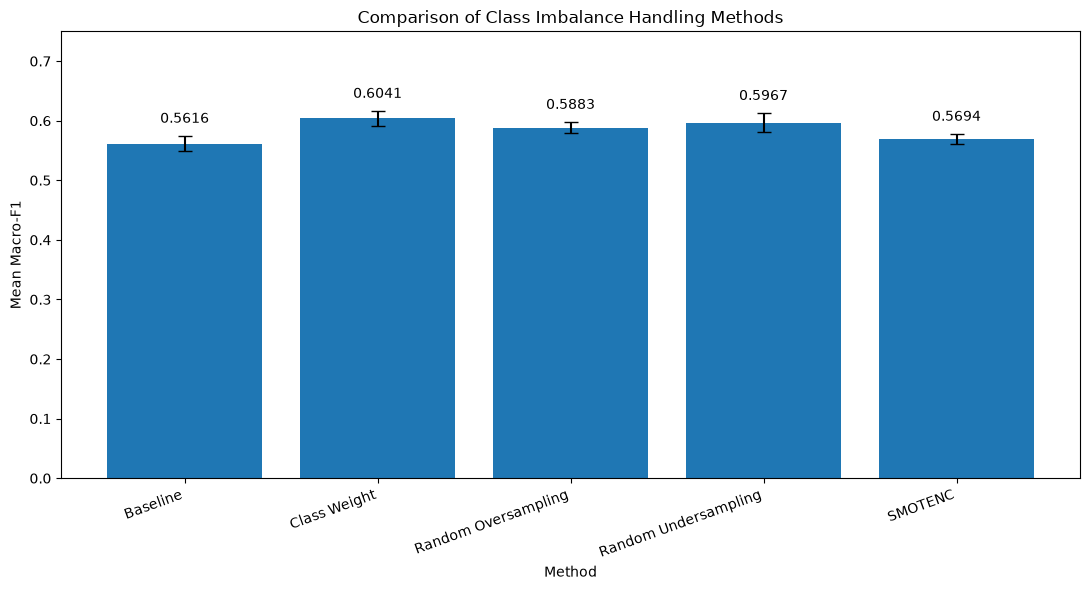

Macro-F1 comparison figure saved successfully!


In [26]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    cv_results["Method"],
    cv_results["Mean Macro-F1"],
    yerr=cv_results["Std Macro-F1"],
    capsize=5
)

ax.set_title("Comparison of Class Imbalance Handling Methods")
ax.set_xlabel("Method")
ax.set_ylabel("Mean Macro-F1")
ax.set_ylim(0, 0.75)

ax.bar_label(bars, fmt="%.4f", padding=7)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

fig.savefig(
    output_dir / "cv_macro_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Macro-F1 comparison figure saved successfully!")

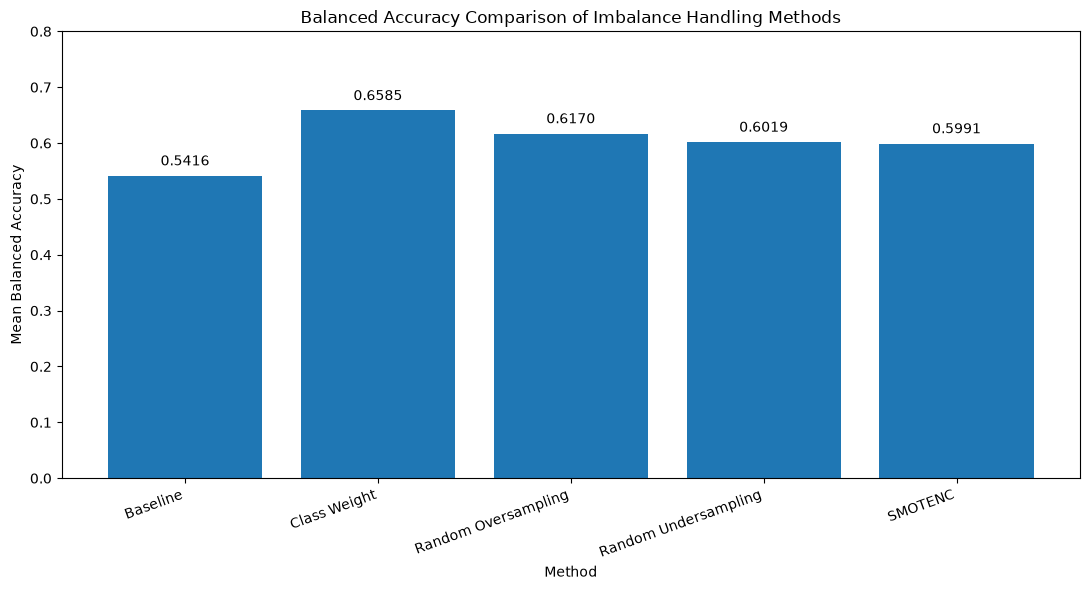

Balanced Accuracy comparison figure saved successfully!


In [27]:
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    cv_results["Method"],
    cv_results["Mean Balanced Accuracy"]
)

ax.set_title("Balanced Accuracy Comparison of Imbalance Handling Methods")
ax.set_xlabel("Method")
ax.set_ylabel("Mean Balanced Accuracy")
ax.set_ylim(0, 0.8)

ax.bar_label(bars, fmt="%.4f", padding=5)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

fig.savefig(
    output_dir / "cv_balanced_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Balanced Accuracy comparison figure saved successfully!")

In [28]:
recall_results = pd.read_csv(
    results_dir / "class_recall_comparison.csv"
)

print(recall_results.to_string(index=False))

         Class  Baseline  Class Weight  Oversampling  Undersampling  SMOTENC
      Analysis  0.132500      0.315000      0.245000       0.210000 0.237500
      Backdoor  0.131805      0.601719      0.553009       0.146132 0.335244
           DoS  0.114554      0.362006      0.365675       0.758255 0.084386
      Exploits  0.917652      0.529570      0.553676       0.579877 0.820332
       Fuzzers  0.734873      0.855886      0.783003       0.871837 0.733773
       Generic  0.979500      0.978500      0.979500       0.978875 0.979625
        Normal  0.914196      0.847232      0.892411       0.839018 0.911518
Reconnaissance  0.751668      0.796473      0.771211       0.789800 0.752622
     Shellcode  0.590308      0.753304      0.643172       0.674009 0.819383
         Worms  0.115385      0.615385      0.500000       0.269231 0.346154


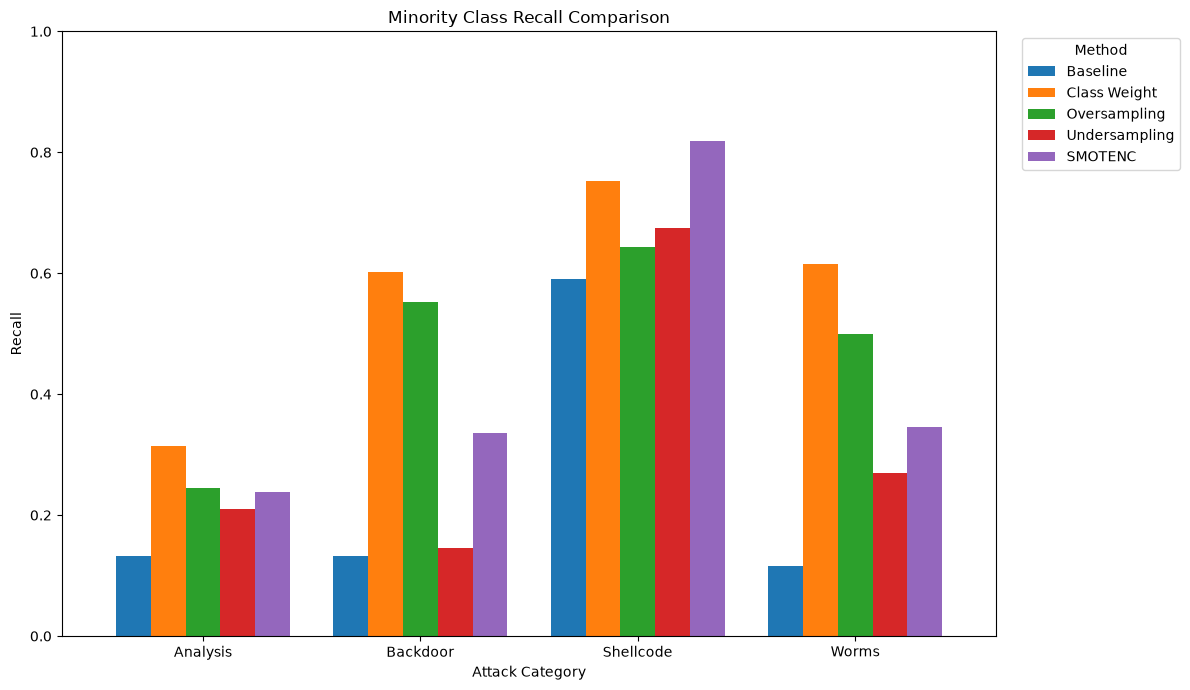

Minority class recall comparison saved successfully!


In [29]:
minority_classes = ["Analysis", "Backdoor", "Shellcode", "Worms"]

minority_recall = recall_results.set_index("Class").loc[minority_classes]

fig, ax = plt.subplots(figsize=(12, 7))

minority_recall.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title("Minority Class Recall Comparison")
ax.set_xlabel("Attack Category")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.0)

ax.legend(
    title="Method",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.xticks(rotation=0)
plt.tight_layout()

fig.savefig(
    output_dir / "minority_class_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Minority class recall comparison saved successfully!")

In [30]:
recall_change = recall_results[["Class", "Baseline", "Class Weight"]].copy()

recall_change["Change (pp)"] = (
    recall_change["Class Weight"] - recall_change["Baseline"]
) * 100

recall_change.to_csv(
    results_dir / "class_weight_recall_changes.csv",
    index=False
)

print(recall_change.round(2).to_string(index=False))
print("Recall changes saved successfully!")

         Class  Baseline  Class Weight  Change (pp)
      Analysis      0.13          0.32        18.25
      Backdoor      0.13          0.60        46.99
           DoS      0.11          0.36        24.75
      Exploits      0.92          0.53       -38.81
       Fuzzers      0.73          0.86        12.10
       Generic      0.98          0.98        -0.10
        Normal      0.91          0.85        -6.70
Reconnaissance      0.75          0.80         4.48
     Shellcode      0.59          0.75        16.30
         Worms      0.12          0.62        50.00
Recall changes saved successfully!


In [31]:
train_data = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test_data = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

feature_cols = train_data.columns.drop(["id", "attack_cat", "label"])

train_hash = pd.util.hash_pandas_object(
    train_data[feature_cols],
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_data[feature_cols],
    index=False
)

overlap_mask = test_hash.isin(set(train_hash))

print("Overlapping test rows:", int(overlap_mask.sum()))
print("Overlap percentage:", f"{overlap_mask.mean():.2%}")

Overlapping test rows: 8541
Overlap percentage: 10.37%


In [32]:
train_pairs = set(zip(
    train_hash.to_numpy(),
    train_data["attack_cat"].to_numpy()
))

test_pairs = zip(
    test_hash.to_numpy(),
    test_data["attack_cat"].to_numpy()
)

label_match_mask = pd.Series(
    [pair in train_pairs for pair in test_pairs],
    index=test_data.index
)

print("Overlapping test rows:", int(overlap_mask.sum()))
print("Matching feature-label rows:", int((overlap_mask & label_match_mask).sum()))
print("Overlapping rows without matching labels:", int((overlap_mask & ~label_match_mask).sum()))
print("Non-overlapping test rows:", int((~overlap_mask).sum()))

Overlapping test rows: 8541
Matching feature-label rows: 4247
Overlapping rows without matching labels: 4294
Non-overlapping test rows: 73791


In [33]:
test_nonoverlap = test_data.loc[~overlap_mask].copy()
test_overlap = test_data.loc[overlap_mask].copy()

print("Official test rows:", len(test_data))
print("Non-overlapping test rows:", len(test_nonoverlap))
print("Overlapping test rows:", len(test_overlap))

print("Non-overlapping class distribution:")
print(test_nonoverlap["attack_cat"].value_counts())

Official test rows: 82332
Non-overlapping test rows: 73791
Overlapping test rows: 8541
Non-overlapping class distribution:
attack_cat
Normal            35528
Generic           17149
Exploits           9330
Fuzzers            5801
Reconnaissance     2358
DoS                2085
Backdoor            579
Analysis            552
Shellcode           365
Worms                44
Name: count, dtype: int64


In [34]:
X_train_full = train_data.drop(columns=["id", "attack_cat", "label"])
y_train_full = train_data["attack_cat"]

X_test_full = test_data.drop(columns=["id", "attack_cat", "label"])
y_test_full = test_data["attack_cat"]

X_test_nonoverlap = test_nonoverlap.drop(columns=["id", "attack_cat", "label"])
y_test_nonoverlap = test_nonoverlap["attack_cat"]

print("Training:", X_train_full.shape)
print("Official test:", X_test_full.shape)
print("Non-overlapping test:", X_test_nonoverlap.shape)

Training: (175341, 42)
Official test: (82332, 42)
Non-overlapping test: (73791, 42)


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

categorical_features = ["proto", "service", "state"]
numeric_features = X_train_full.select_dtypes(include="number").columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

final_model = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

final_model.fit(X_train_full, y_train_full)

print("Final Class Weight Random Forest trained successfully!")

Final Class Weight Random Forest trained successfully!


In [36]:
y_pred_full = final_model.predict(X_test_full)

y_pred_nonoverlap = final_model.predict(X_test_nonoverlap)

print("Official test predictions:", len(y_pred_full))
print("Non-overlapping test predictions:", len(y_pred_nonoverlap))

Official test predictions: 82332
Non-overlapping test predictions: 73791


In [37]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

final_comparison = pd.DataFrame([
    {
        "Dataset": "Official Test",
        "Samples": len(y_test_full),
        "Accuracy": accuracy_score(y_test_full, y_pred_full),
        "Macro-F1": f1_score(y_test_full, y_pred_full, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_test_full, y_pred_full)
    },
    {
        "Dataset": "Non-overlapping Test",
        "Samples": len(y_test_nonoverlap),
        "Accuracy": accuracy_score(y_test_nonoverlap, y_pred_nonoverlap),
        "Macro-F1": f1_score(y_test_nonoverlap, y_pred_nonoverlap, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_test_nonoverlap, y_pred_nonoverlap)
    }
])

print(final_comparison.round(4).to_string(index=False))

             Dataset  Samples  Accuracy  Macro-F1  Balanced Accuracy
       Official Test    82332    0.6921    0.5010             0.5871
Non-overlapping Test    73791    0.7242    0.5328             0.6208


In [38]:
from pathlib import Path

output_dir = Path("../results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(
    output_dir / "final_test_comparison.csv",
    index=False
)

print("Final test comparison saved successfully!")

Final test comparison saved successfully!


In [39]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_full,
    y_pred_full,
    digits=4,
    zero_division=0
))

                precision    recall  f1-score   support

      Analysis     0.0079    0.0222    0.0116       677
      Backdoor     0.0502    0.5763    0.0924       583
           DoS     0.3794    0.1712    0.2359      4089
      Exploits     0.7808    0.6337    0.6996     11132
       Fuzzers     0.2595    0.7181    0.3812      6062
       Generic     0.9996    0.9636    0.9813     18871
        Normal     0.9895    0.6240    0.7653     37000
Reconnaissance     0.8496    0.8372    0.8434      3496
     Shellcode     0.2816    0.8016    0.4168       378
         Worms     0.6571    0.5227    0.5823        44

      accuracy                         0.6921     82332
     macro avg     0.5255    0.5871    0.5010     82332
  weighted avg     0.8554    0.6921    0.7420     82332



In [40]:
from sklearn.metrics import classification_report

final_report = pd.DataFrame(
    classification_report(
        y_test_full,
        y_pred_full,
        output_dict=True,
        zero_division=0
    )
).T

final_report.to_csv(
    output_dir / "final_weighted_classification_report.csv"
)

print("Final classification report saved successfully!")

Final classification report saved successfully!


In [41]:
baseline_report = pd.read_csv(
    "../results/tables/random_forest_classification_report.csv",
    index_col=0
)

classes = sorted(y_test_full.unique())

class_comparison = pd.DataFrame({
    "Class": classes,
    "Baseline Recall": baseline_report.loc[classes, "recall"].values,
    "Weighted Recall": final_report.loc[classes, "recall"].values,
    "Baseline F1": baseline_report.loc[classes, "f1-score"].values,
    "Weighted F1": final_report.loc[classes, "f1-score"].values
})

class_comparison["Recall Change (pp)"] = (
    class_comparison["Weighted Recall"] - class_comparison["Baseline Recall"]
) * 100

print(class_comparison.round(4).to_string(index=False))

         Class  Baseline Recall  Weighted Recall  Baseline F1  Weighted F1  Recall Change (pp)
      Analysis           0.0030           0.0222       0.0022       0.0116              1.9202
      Backdoor           0.0892           0.5763       0.0280       0.0924             48.7136
           DoS           0.0968           0.1712       0.1678       0.2359              7.4346
      Exploits           0.7845           0.6337       0.6933       0.6996            -15.0826
       Fuzzers           0.5945           0.7181       0.3933       0.3812             12.3557
       Generic           0.9678           0.9636       0.9830       0.9813             -0.4133
        Normal           0.7570           0.6240       0.8473       0.7653            -13.3054
Reconnaissance           0.8006           0.8372       0.8554       0.8434              3.6613
     Shellcode           0.6667           0.8016       0.4941       0.4168             13.4921
         Worms           0.0682           0.5227  

In [42]:
class_comparison.to_csv(
    output_dir / "final_class_comparison.csv",
    index=False
)

print("Final class comparison saved successfully!")

Final class comparison saved successfully!


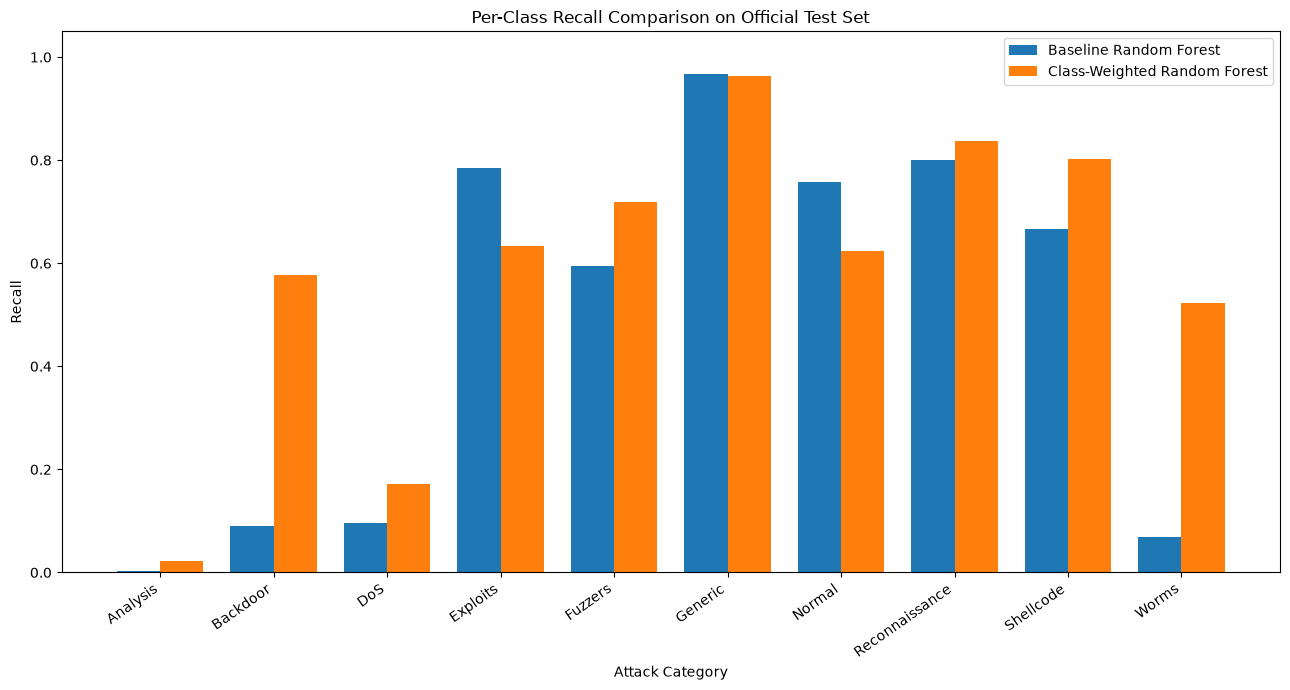

Final class recall comparison saved successfully!


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

classes = class_comparison["Class"]
x = np.arange(len(classes))
width = 0.38

fig, ax = plt.subplots(figsize=(13, 7))

ax.bar(
    x - width / 2,
    class_comparison["Baseline Recall"],
    width,
    label="Baseline Random Forest"
)

ax.bar(
    x + width / 2,
    class_comparison["Weighted Recall"],
    width,
    label="Class-Weighted Random Forest"
)

ax.set_title("Per-Class Recall Comparison on Official Test Set")
ax.set_xlabel("Attack Category")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.05)
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=35, ha="right")
ax.legend()

fig.tight_layout()

fig.savefig(
    output_dir / "final_class_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final class recall comparison saved successfully!")

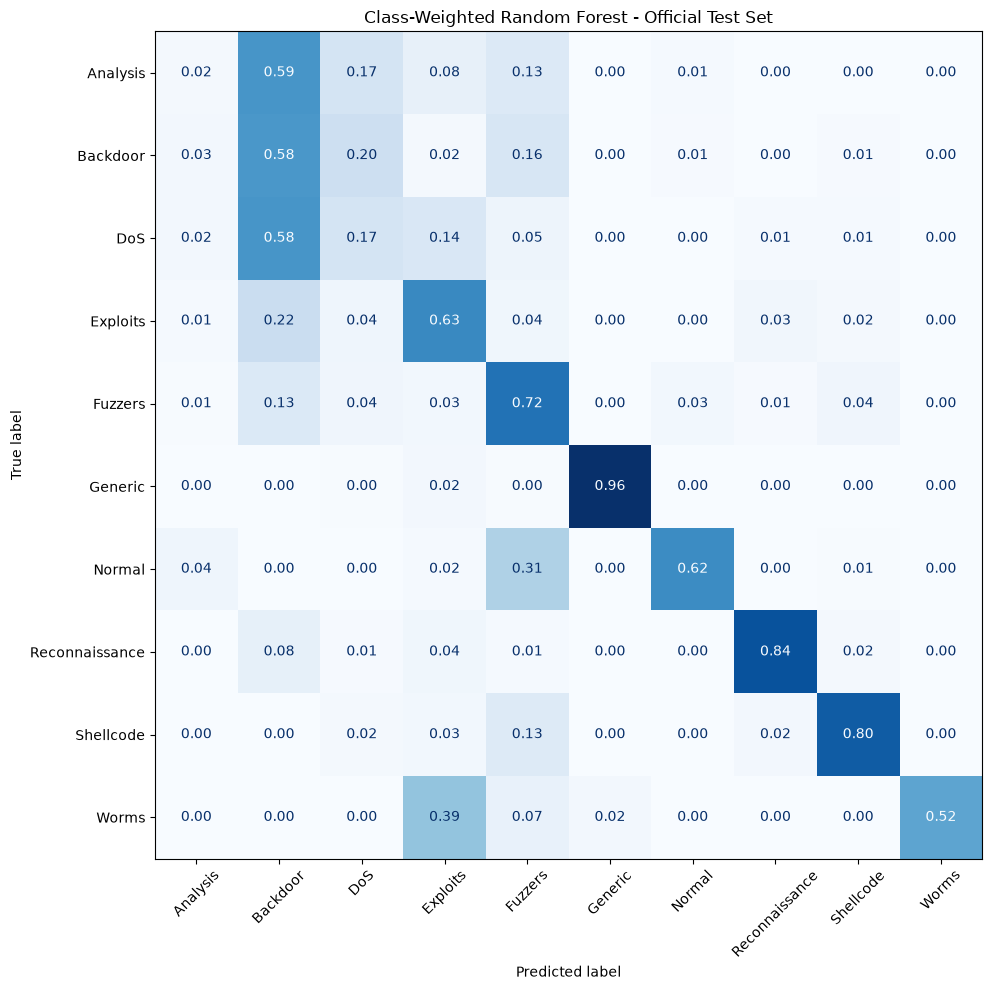

Final weighted confusion matrix saved successfully!


In [44]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

classes = sorted(y_test_full.unique())

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test_full,
    y_pred_full,
    labels=classes,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)

ax.set_title("Class-Weighted Random Forest - Official Test Set")

fig.tight_layout()

fig.savefig(
    output_dir / "final_weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final weighted confusion matrix saved successfully!")

In [45]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

classes = sorted(y_test_full.unique())

cm_counts = confusion_matrix(
    y_test_full,
    y_pred_full,
    labels=classes
)

cm_errors = cm_counts.copy()
np.fill_diagonal(cm_errors, 0)

errors_df = pd.DataFrame(
    cm_errors,
    index=classes,
    columns=classes
)

errors_long = errors_df.stack().reset_index()
errors_long.columns = ["True Class", "Predicted Class", "Count"]

top_errors = errors_long[
    errors_long["Count"] > 0
].nlargest(10, "Count")

tables_dir = Path("../results/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

top_errors.to_csv(
    tables_dir / "final_top_misclassifications.csv",
    index=False
)

print(top_errors.to_string(index=False))
print("Misclassification analysis saved successfully!")

True Class Predicted Class  Count
    Normal         Fuzzers  11442
  Exploits        Backdoor   2447
       DoS        Backdoor   2391
    Normal        Analysis   1584
   Fuzzers        Backdoor    807
       DoS        Exploits    585
    Normal        Exploits    556
  Exploits             DoS    480
   Generic        Exploits    453
  Exploits         Fuzzers    415
Misclassification analysis saved successfully!


In [46]:
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
from pathlib import Path

classes = sorted(y_test_full.unique())

cm = confusion_matrix(
    y_test_full,
    y_pred_full,
    labels=classes
)

tp = np.diag(cm)
predicted_count = cm.sum(axis=0)
fp = predicted_count - tp

precision = np.divide(
    tp,
    predicted_count,
    out=np.zeros(len(tp), dtype=float),
    where=predicted_count != 0
)

fp_summary = pd.DataFrame({
    "Class": classes,
    "Predicted Count": predicted_count,
    "Correct Predictions": tp,
    "False Positives": fp,
    "Precision": precision
})

fp_summary = fp_summary.sort_values(
    "False Positives",
    ascending=False
)

output_dir = Path("../results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

fp_summary.to_csv(
    output_dir / "final_false_positive_analysis.csv",
    index=False
)

print(fp_summary.round(4).to_string(index=False))
print("False positive analysis saved successfully!")

         Class  Predicted Count  Correct Predictions  False Positives  Precision
       Fuzzers            16774                 4353            12421     0.2595
      Backdoor             6687                  336             6351     0.0502
      Exploits             9034                 7054             1980     0.7808
      Analysis             1910                   15             1895     0.0079
           DoS             1845                  700             1145     0.3794
     Shellcode             1076                  303              773     0.2816
Reconnaissance             3445                 2927              518     0.8496
        Normal            23333                23087              246     0.9895
         Worms               35                   23               12     0.6571
       Generic            18193                18185                8     0.9996
False positive analysis saved successfully!


In [47]:
precision_comparison = pd.DataFrame({
    "Class": classes,
    "Baseline Precision": baseline_report.loc[classes, "precision"].values,
    "Weighted Precision": final_report.loc[classes, "precision"].values
})

precision_comparison["Precision Change (pp)"] = (
    precision_comparison["Weighted Precision"]
    - precision_comparison["Baseline Precision"]
) * 100

precision_comparison.to_csv(
    output_dir / "final_precision_comparison.csv",
    index=False
)

print(precision_comparison.round(4).to_string(index=False))
print("Precision comparison saved successfully!")

         Class  Baseline Precision  Weighted Precision  Precision Change (pp)
      Analysis              0.0017              0.0079                 0.6117
      Backdoor              0.0166              0.0502                 3.3617
           DoS              0.6276              0.3794               -24.8171
      Exploits              0.6212              0.7808                15.9660
       Fuzzers              0.2938              0.2595                -3.4336
       Generic              0.9986              0.9996                 0.0927
        Normal              0.9621              0.9895                 2.7377
Reconnaissance              0.9183              0.8496                -6.8670
     Shellcode              0.3925              0.2816               -11.0925
         Worms              0.5000              0.6571                15.7143
Precision comparison saved successfully!
